In [ ]:
import pandas as pd
import numpy as np
import gc
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

In [ ]:
# [전처리 함수] 승준 님의 기존 로직을 유지하되, r'(\d+)'로 경고를 방지했습니다.
def get_clean(target_df, val_idx):
    if len(target_df) == 0:
        return pd.DataFrame(columns=['열1', '값'])

    res = pd.DataFrame()
    res['일자_base'] = pd.to_datetime(target_df.iloc[:, 0], errors='coerce')

    # 시간(h), 분(m) 추출 - Raw string(r) 사용으로 SyntaxWarning 방지
    h = target_df.iloc[:, 5].astype(str).str.extract(r'(\d+)').fillna('00')
    m = target_df.iloc[:, 7].astype(str).str.extract(r'(\d+)').fillna('00')

    res = res.dropna(subset=['일자_base'])

    # 진짜 시계열 '열1' 생성
    res['열1'] = pd.to_datetime(
        res['일자_base'].dt.strftime('%Y-%m-%d') + ' ' + h[0].str.zfill(2) + ':' + m[0].str.zfill(2) + ':00'
    )

    res['값'] = pd.to_numeric(target_df.iloc[:, val_idx], errors='coerce')
    return res[['열1', '값']]

In [ ]:
def get_clean_minimal(target_df, val_idx, name, type_label):
    if target_df.empty:
        return pd.DataFrame(columns=['열1', f'{name}_{type_label}'])

    # 시간 추출 최적화 (열 번호 기반)
    # iloc[:, 0]: 날짜, iloc[:, 5]: 시, iloc[:, 7]: 분
    base_date = pd.to_datetime(target_df.iloc[:, 0], errors='coerce')
    h = target_df.iloc[:, 5].astype(str).str.extract(r'(\d+)').fillna('00')[0].str.zfill(2)
    m = target_df.iloc[:, 7].astype(str).str.extract(r'(\d+)').fillna('00')[0].str.zfill(2)

    res = pd.DataFrame({
        '열1': pd.to_datetime(base_date.dt.strftime('%Y-%m-%d') + ' ' + h + ':' + m + ':00'),
        f'{name}_{type_label}': pd.to_numeric(target_df.iloc[:, val_idx], errors='coerce')
    }).dropna(subset=['열1'])

    return res

file_list = {'구간1': '구간1.xlsx', '구간2': '구간2.xlsx', '구간3': '구간3.xlsx'}
df_final = None

for name, path in file_list.items():
    print(f"🔄 {name} 처리 중...")

🔄 구간1 처리 중...
🔄 구간2 처리 중...
🔄 구간3 처리 중...


In [ ]:
# 1. 필요한 열만 지정해서 읽기 (메모리 절약의 핵심)
    # 엑셀의 모든 열이 아닌, 날짜/시간/지표명이 포함된 열만 골라 읽습니다.
    # 지표명이 포함된 열 인덱스(예: 4번)를 알고 있다면 usecols를 쓰면 더 좋습니다.
raw = pd.read_excel(path)

# 2. 불필요한 apply 대신 특정 컬럼(예: 4번 열) 조건검색으로 변경
# 보통 '지점총교통량' 문구는 특정 열에만 있으므로 iloc[:, 4] 식으로 지정하면 훨씬 빠릅니다.
label_col = raw.iloc[:, 4].astype(str)
vol_raw = raw[label_col.str.contains('지점총교통량')].copy()
speed_raw = raw[label_col.str.contains('평균통행속도')].copy()

del raw
gc.collect()

12159

In [ ]:
# 3. 데이터 정제 및 타입 변환 (float32로 용량 절반 축소)
v_df = get_clean_minimal(vol_raw, 8, name, '교통')
s_idx = 10 if speed_raw.shape[1] > 10 else speed_raw.shape[1]-1
s_df = get_clean_minimal(speed_raw, s_idx, name, '속도')

    # 숫자 데이터 용량 줄이기
v_df.iloc[:, 1] = v_df.iloc[:, 1].astype('float32')
s_df.iloc[:, 1] = s_df.iloc[:, 1].astype('float32')

combined = pd.merge(v_df, s_df, on='열1', how='inner')

del vol_raw, speed_raw, v_df, s_df
gc.collect()

0

In [ ]:
file_list = {'구간1': '구간1.xlsx', '구간2': '구간2.xlsx', '구간3': '구간3.xlsx'}
df_final = None

# 1. 반복문을 통해 구간별 데이터 처리 및 병합을 한 번에 수행
for name, path in file_list.items():
    print(f"🔄 {name} 처리 중...")

    # 파일 읽기 및 필터링
    raw = pd.read_excel(path)
    label_col = raw.iloc[:, 4].astype(str)
    vol_raw = raw[label_col.str.contains('지점총교통량')].copy()
    speed_raw = raw[label_col.str.contains('평균통행속도')].copy()
    del raw
    gc.collect()

    # 데이터 정제 (v_df, s_df 생성)
    v_df = get_clean_minimal(vol_raw, 8, name, '교통')
    s_idx = 10 if speed_raw.shape[1] > 10 else speed_raw.shape[1]-1
    s_df = get_clean_minimal(speed_raw, s_idx, name, '속도')

    # [핵심] 여기서 combined가 정의됩니다.
    combined = pd.merge(v_df, s_df, on='열1', how='inner')
    del vol_raw, speed_raw, v_df, s_df
    gc.collect()

    # 최종 병합
    if df_final is None:
        df_final = combined
    else:
        # 데이터 증발 방지를 위해 how='outer'를 권장합니다.
        df_final = pd.merge(df_final, combined, on='열1', how='outer')
        del combined
        gc.collect()

# 2. 최종 파생변수 생성 및 후처리
if df_final is not None:
    # 시간 순서 정렬 및 결측치 채우기
    df_final = df_final.sort_values('열1').ffill().bfill()

    # 날짜 형식 강제 변환 (AttributeError 방지)
    df_final['열1'] = pd.to_datetime(df_final['열1'], errors='coerce')
    df_final = df_final.dropna(subset=['열1'])

    # 파생변수 추가
    df_final['요일'] = df_final['열1'].dt.dayofweek.astype('int8')
    df_final['시간'] = df_final['열1'].dt.hour.astype('int8')
    df_final['주말여부'] = (df_final['요일'] >= 5).astype('int8')

    print("\n✨ 모든 데이터 통합 및 파생변수 생성 완료!")
    display(df_final.head())

🔄 구간1 처리 중...
🔄 구간2 처리 중...
🔄 구간3 처리 중...

✨ 모든 데이터 통합 및 파생변수 생성 완료!


,열1,구간1_교통,구간1_속도,구간2_교통,구간2_속도,구간3_교통,구간3_속도,요일,시간,주말여부


In [ ]:
def get_clean_optimized(path, name):
    # 1. 엑셀 읽기 (필요한 열만 지정해서 읽어 메모리 절약)
    # A(일자), F(시), G(분), I(교통량값), K(속도값) 추출
    raw = pd.read_excel(path, usecols=[0, 5, 6, 8, 10])

    # 2. 시간 데이터 생성
    # F열(시), G열(분)에서 숫자만 추출
    h = raw.iloc[:, 1].astype(str).str.extract(r'(\d+)').fillna('00')[0].str.zfill(2)
    m = raw.iloc[:, 2].astype(str).str.extract(r'(\d+)').fillna('00')[0].str.zfill(2)

    df = pd.DataFrame({
        '열1': pd.to_datetime(raw.iloc[:, 0].dt.strftime('%Y-%m-%d') + ' ' + h + ':' + m + ':00'),
        f'{name}_교통': pd.to_numeric(raw.iloc[:, 3], errors='coerce'),
        f'{name}_속도': pd.to_numeric(raw.iloc[:, 4], errors='coerce')
    })

    # 3. 15분 단위 반올림 및 결측치 제거
    df = df.dropna(subset=['열1'])
    df['열1'] = df['열1'].dt.round('15min')

    del raw
    gc.collect()
    return df

# --- 병합 프로세스 시작 ---
file_list = {'구간1': '구간1.xlsx', '구간2': '구간2.xlsx', '구간3': '구간3.xlsx'}
df_final = None

for name, path in file_list.items():
    print(f"🔄 {name} 처리 중...")
    processed = get_clean_optimized(path, name)

    if df_final is None:
        df_final = processed
    else:
        # 시간 기준 병합 (데이터 유실 방지를 위해 outer 사용)
        df_final = pd.merge(df_final, processed, on='열1', how='outer')

    del processed
    gc.collect()

# --- 최종 후처리 및 학습 준비 ---
if df_final is not None and not df_final.empty:
    df_final = df_final.sort_values('열1').ffill().bfill().drop_duplicates('열1')

    # 파생변수 (메모리 절약형 타입)
    df_final['요일'] = df_final['열1'].dt.dayofweek.astype('int8')
    df_final['시간'] = df_final['열1'].dt.hour.astype('int8')
    df_final['주말여부'] = (df_final['요일'] >= 5).astype('int8')

    print(f"✅ 데이터 통합 성공! 총 {len(df_final)}건 확보.")

    # LSTM용 데이터셋 생성 (구간1_속도 예측)
    features = [col for col in df_final.columns if col not in ['열1', '요일', '시간', '주말여부']]
    target_idx = features.index('구간1_속도')

    scaler = MinMaxScaler()
    df_scaled = scaler.fit_transform(df_final[features])

    def create_dataset(data, look_back=8):
        X, y = [], []
        for i in range(len(data) - look_back):
            X.append(data[i:(i + look_back), :])
            y.append(data[i + look_back, target_idx])
        return np.array(X), np.array(y)

    X_train_val, y_train_val = create_dataset(df_scaled, 8)
    # ... 이후 모델 학습 코드 실행 ...
    print(f"✅ 학습 준비 완료! X_train 형상: {X_train_val.shape}")
else:
    print("❌ 데이터를 가져오지 못했습니다. 파일 경로를 확인해주세요.")

🔄 구간1 처리 중...
🔄 구간2 처리 중...
🔄 구간3 처리 중...
✅ 데이터 통합 성공! 총 11988건 확보.
✅ 학습 준비 완료! X_train 형상: (11980, 8, 6)


In [ ]:
# 1. 특징(features) 정의 및 스케일링
# '열1', '요일', '시간', '주말여부'를 제외한 모든 컬럼을 사용합니다.
features = [col for col in df_final.columns if col not in ['열1', '요일', '시간', '주말여부']]
target_idx = features.index('구간1_속도')

scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_final[features])

# 2. 시계열 데이터셋 생성 함수
def create_dataset(data, look_back=8):
    X_list, y_list = [], []
    for i in range(len(data) - look_back):
        X_list.append(data[i:(i + look_back), :])
        y_list.append(data[i + look_back, target_idx])
    return np.array(X_list), np.array(y_list)

# 3. X, y 데이터 생성 (여기서 X_train이 정의됩니다)
X, y = create_dataset(df_scaled, 8)
train_size = int(len(X) * 0.8)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"✅ 데이터 준비 완료! X_train 형상: {X_train.shape}")

✅ 데이터 준비 완료! X_train 형상: (9584, 8, 6)


In [ ]:
# 모델 구성
model = Sequential([
    LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

# 모델 학습 (Epoch를 30으로 설정)
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


270/270 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - loss: 0.0125 - val_loss: 0.0046
Epoch 2/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - loss: 0.0043 - val_loss: 0.0034
Epoch 3/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0036 - val_loss: 0.0035
Epoch 4/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0032 - val_loss: 0.0044
Epoch 5/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - loss: 0.0030 - val_loss: 0.0038
Epoch 6/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0028 - val_loss: 0.0043
Epoch 7/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0027 - val_loss: 0.0037
Epoch 8/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0027 - val_loss: 0.0036
Epoch 9/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0025 - val_loss: 0.0026
Epoch 10/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0025 - val_loss: 0.0025
Epoch 11/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0024 - val_loss: 0.0034
Epoch 12/30
270/270 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/s

75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


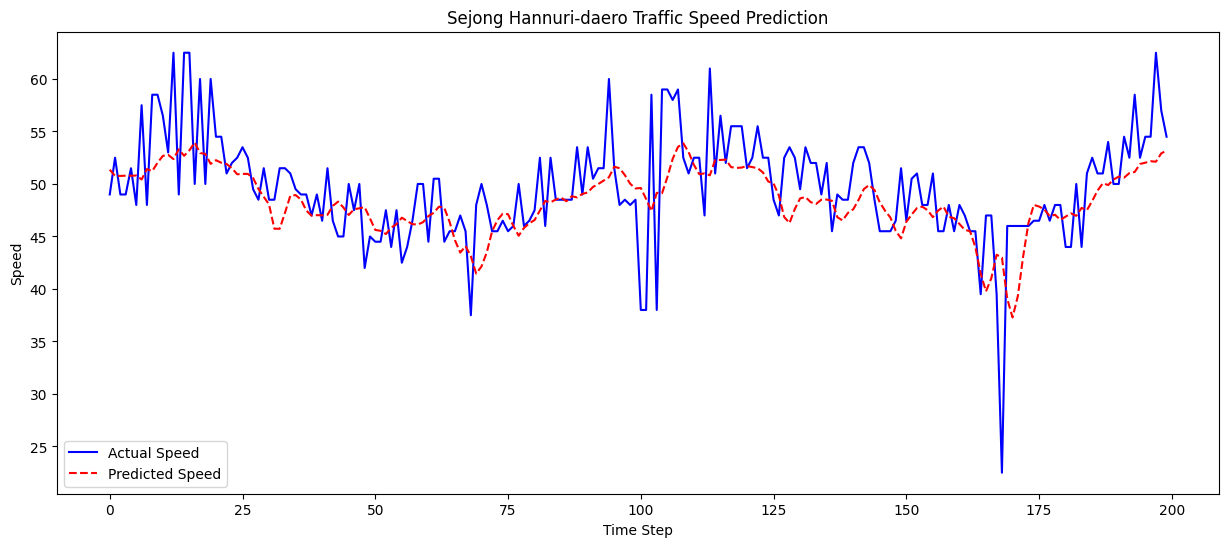

In [ ]:
# 예측
y_pred = model.predict(X_test)
dummy = np.zeros((len(y_test), len(features)))

# 실제값 및 예측값 역정규화
dummy[:, target_idx] = y_test.flatten()
y_test_unscaled = scaler.inverse_transform(dummy)[:, target_idx]

dummy[:, target_idx] = y_pred.flatten()
y_pred_unscaled = scaler.inverse_transform(dummy)[:, target_idx]

# 시각화
plt.figure(figsize=(15, 6))
plt.plot(y_test_unscaled[:200], label='Actual Speed', color='blue')
plt.plot(y_pred_unscaled[:200], label='Predicted Speed', color='red', linestyle='--')
plt.title('Sejong Hannuri-daero Traffic Speed Prediction')
plt.xlabel('Time Step')
plt.ylabel('Speed')
plt.legend()
plt.show()

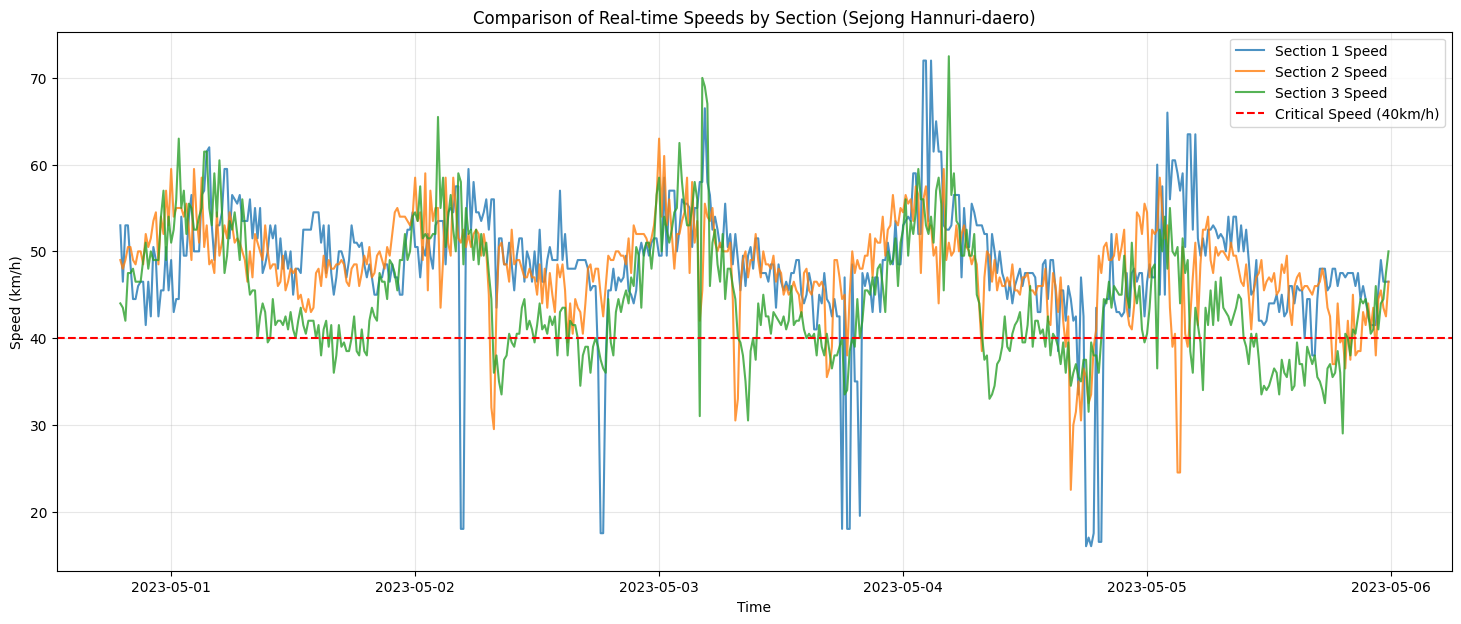

In [ ]:
# 시각화할 샘플 데이터 개수 설정 (예: 최근 500개 데이터)
sample_n = 500

plt.figure(figsize=(18, 7))

# 각 구간의 실제 속도 그래프 출력 (역스케일링 전이라면 df_final 사용 가능)
plt.plot(df_final['열1'].iloc[-sample_n:], df_final['구간1_속도'].iloc[-sample_n:], label='Section 1 Speed', alpha=0.8)
plt.plot(df_final['열1'].iloc[-sample_n:], df_final['구간2_속도'].iloc[-sample_n:], label='Section 2 Speed', alpha=0.8)
plt.plot(df_final['열1'].iloc[-sample_n:], df_final['구간3_속도'].iloc[-sample_n:], label='Section 3 Speed', alpha=0.8)

# 임계 속도 기준선 추가 (운영 전략 근거용)
plt.axhline(y=40, color='red', linestyle='--', label='Critical Speed (40km/h)')

plt.title('Comparison of Real-time Speeds by Section (Sejong Hannuri-daero)')
plt.xlabel('Time')
plt.ylabel('Speed (km/h)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

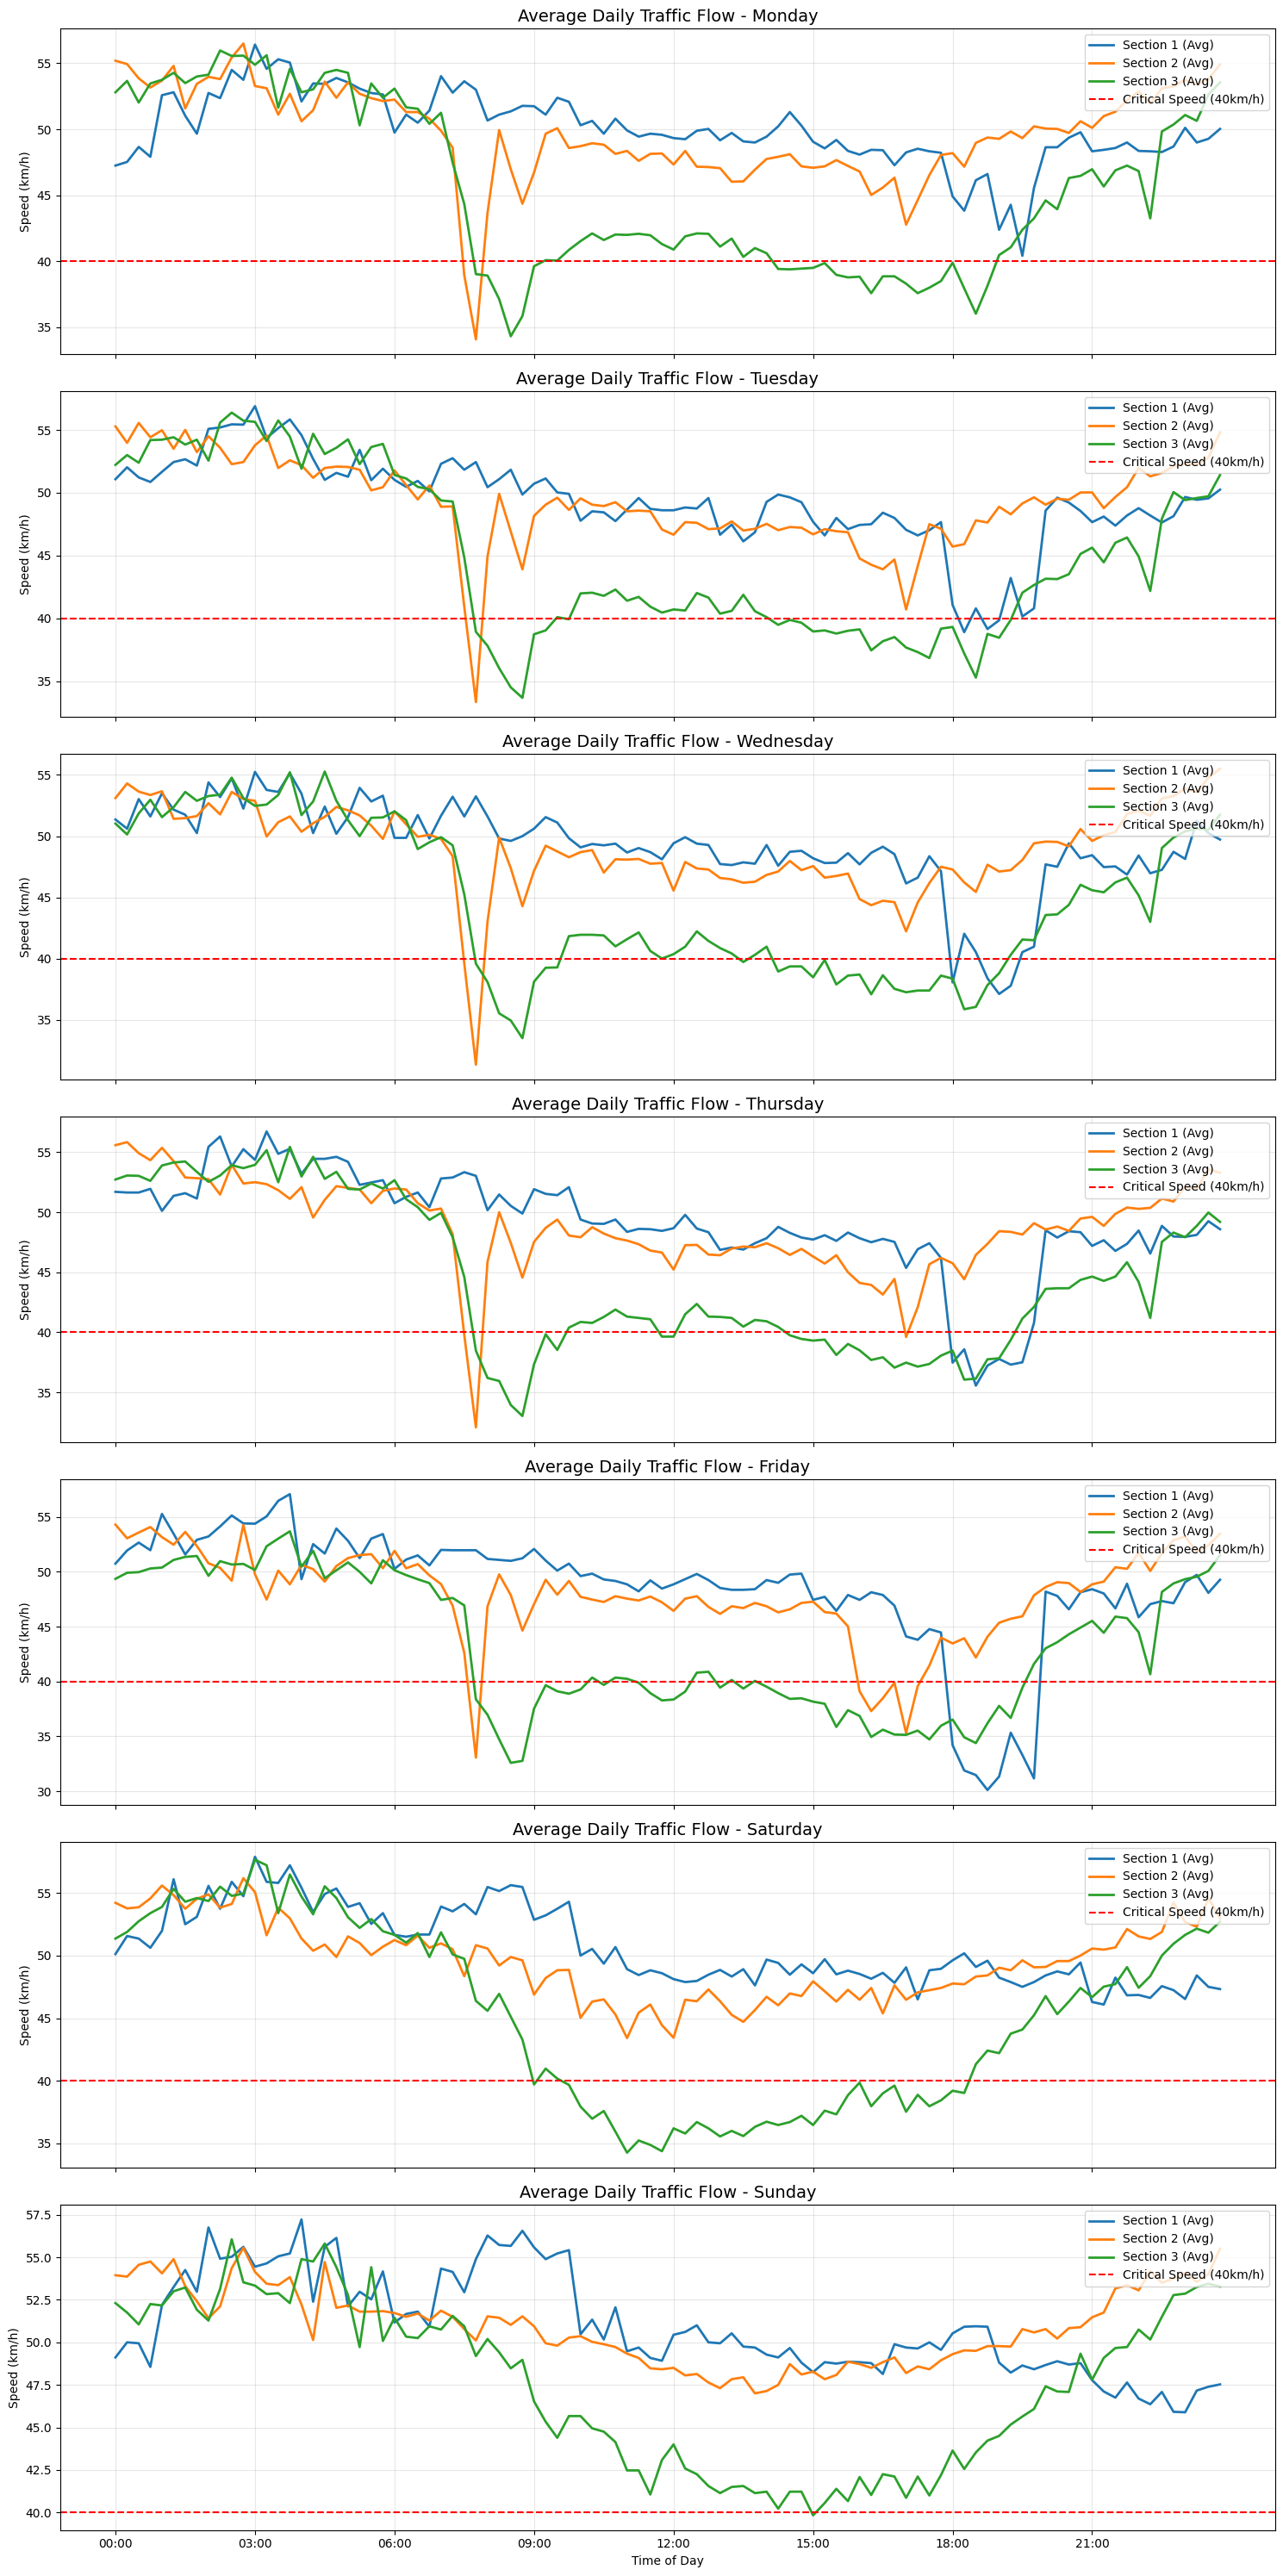

In [ ]:
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
fig, axes = plt.subplots(7, 1, figsize=(15, 30), sharex=True)

for i in range(7):
    # 해당 요일 데이터 추출
    day_df = df_final[df_final['요일'] == i].copy()

    # [핵심] 시간대(00:00~23:45)별로 평균(mean) 계산
    day_avg = day_df.groupby(day_df['열1'].dt.time).mean(numeric_only=True)

    # x축 시간 레이블 생성
    time_labels = [t.strftime('%H:%M') for t in day_avg.index]

    # 그래프 출력
    axes[i].plot(time_labels, day_avg['구간1_속도'], label='Section 1 (Avg)', linewidth=2)
    axes[i].plot(time_labels, day_avg['구간2_속도'], label='Section 2 (Avg)', linewidth=2)
    axes[i].plot(time_labels, day_avg['구간3_속도'], label='Section 3 (Avg)', linewidth=2)

    axes[i].axhline(y=40, color='red', linestyle='--', label='Critical Speed (40km/h)')
    axes[i].set_title(f'Average Daily Traffic Flow - {days[i]}', fontsize=14)
    axes[i].set_ylabel('Speed (km/h)')
    axes[i].legend(loc='upper right')
    axes[i].grid(True, alpha=0.3)

    # x축 간격 조절
    axes[i].set_xticks(range(0, len(time_labels), 12))

plt.xlabel('Time of Day')
plt.tight_layout()
plt.show()

In [ ]:
# 1. 요일별/시간별 평균 데이터 재계산
df_final['time_only'] = df_final['열1'].dt.time
avg_pattern = df_final.groupby(['요일', 'time_only']).mean(numeric_only=True).reset_index()

critical_points = []
days_map = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 4: 'Friday', 5: 'Saturday', 6: 'Sunday'}

# 2. 임계점(40km/h) 하향 돌파 시점 추출
for day in range(7):
    day_data = avg_pattern[avg_pattern['요일'] == day].sort_values('time_only')

    row = {'Day': days_map[day]}
    for section in ['구간1_속도', '구간2_속도', '구간3_속도']:
        # 속도가 40 미만으로 떨어지는 첫 번째 시각 찾기 (주로 오전 피크 기준)
        drop_points = day_data[day_data[section] < 40]
        if not drop_points.empty:
            row[section.split('_')[0]] = drop_points.iloc[0]['time_only'].strftime('%H:%M')
        else:
            row[section.split('_')[0]] = "N/A"

    critical_points.append(row)

# 3. 표(DataFrame) 생성 및 출력
cp_table = pd.DataFrame(critical_points)
print("📌 요일별 정체 진입 시점 (40km/h 하향 돌파 시각)")
display(cp_table)

# 4. 상관관계 분석 (시차 계산)
# 예: 구간1과 구간2 사이의 시차(분) 계산 로직 추가 가능

📌 요일별 정체 진입 시점 (40km/h 하향 돌파 시각)


,Day,구간1,구간2,구간3
0,Monday,N/A,07:30,07:45
1,Tuesday,18:15,07:45,07:45
2,Wednesday,18:00,07:30,07:45
3,Thursday,18:00,07:30,07:45
4,Friday,18:00,07:45,07:45
5,Saturday,N/A,N/A,09:00
6,Sunday,N/A,N/A,15:00


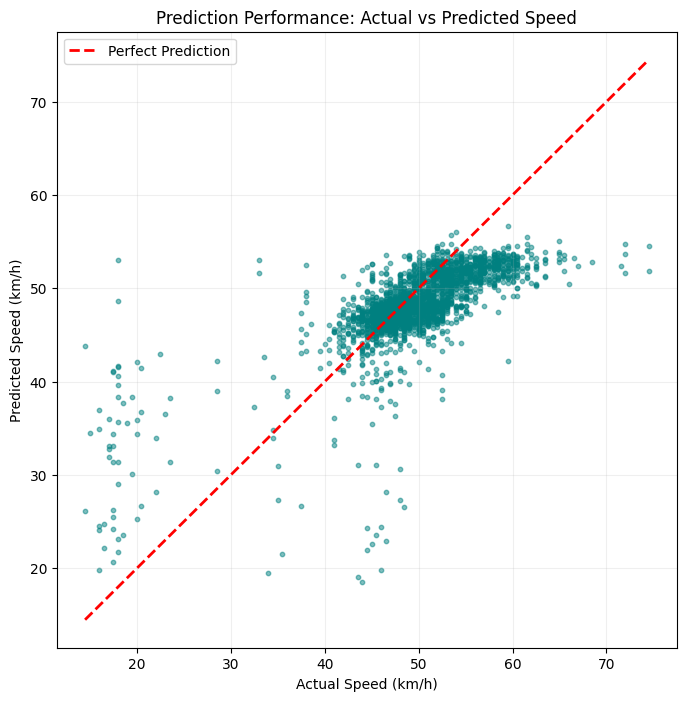

In [ ]:
# 산점도 시각화
plt.figure(figsize=(8, 8))

# 실제값(y_test_unscaled)과 예측값(y_pred_unscaled) 비교
plt.scatter(y_test_unscaled, y_pred_unscaled, alpha=0.5, color='teal', s=10)

# 기준선 (완벽한 예측일 때의 직선)
max_val = max(np.max(y_test_unscaled), np.max(y_pred_unscaled))
min_val = min(np.min(y_test_unscaled), np.min(y_pred_unscaled))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Perfect Prediction')

plt.title('Prediction Performance: Actual vs Predicted Speed')
plt.xlabel('Actual Speed (km/h)')
plt.ylabel('Predicted Speed (km/h)')
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step


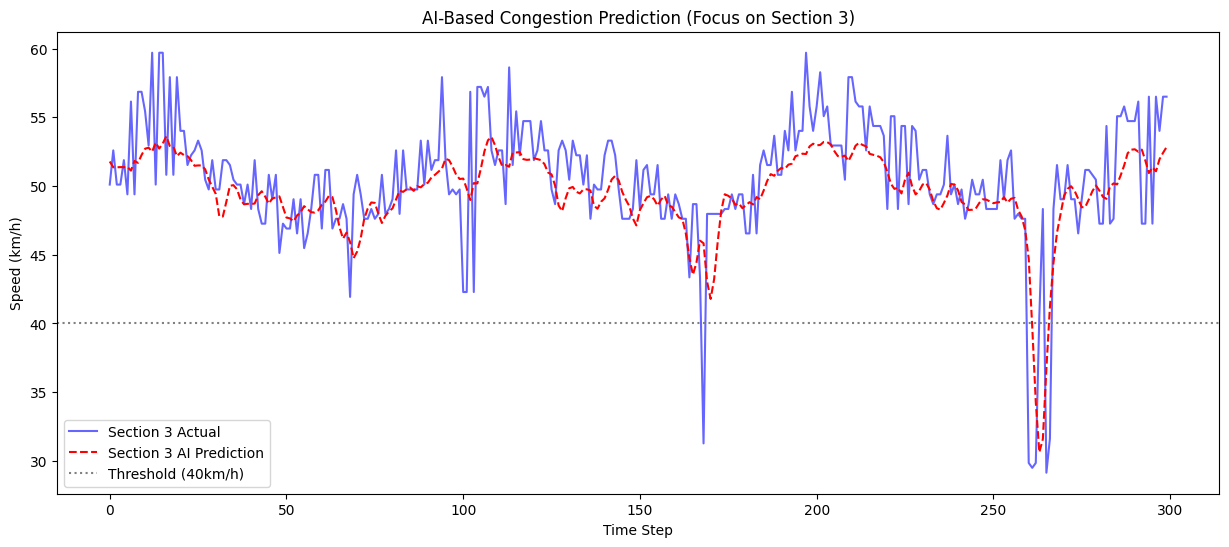

In [ ]:
target_idx_s3 = features.index('구간3_속도')

# 예측 (구간 3 기준)
y_pred_s3 = model.predict(X_test)

# 실제값 및 예측값 역정규화를 위한 더미 배열 생성 (구간 3 기준)
dummy_s3 = np.zeros((len(y_test), len(features)))

# 실제값 역정규화 (구간 3)
dummy_s3[:, target_idx_s3] = y_test.flatten()
y_test_unscaled_s3 = scaler.inverse_transform(dummy_s3)[:, target_idx_s3]

# 예측값 역정규화 (구간 3)
dummy_s3[:, target_idx_s3] = y_pred_s3.flatten()
y_pred_unscaled_s3 = scaler.inverse_transform(dummy_s3)[:, target_idx_s3]

plt.figure(figsize=(15, 6))
# 1. 구간 3 실제 데이터 (파란색)
plt.plot(y_test_unscaled_s3[:300], label='Section 3 Actual', color='blue', alpha=0.6)
# 2. 구간 3 LSTM 예측 데이터 (빨간색 점선)
plt.plot(y_pred_unscaled_s3[:300], label='Section 3 AI Prediction', color='red', linestyle='--')

# 3. 임계점 가이드라인
plt.axhline(y=40, color='gray', linestyle=':', label='Threshold (40km/h)')

plt.title('AI-Based Congestion Prediction (Focus on Section 3)')
plt.xlabel('Time Step')
plt.ylabel('Speed (km/h)')
plt.legend()
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


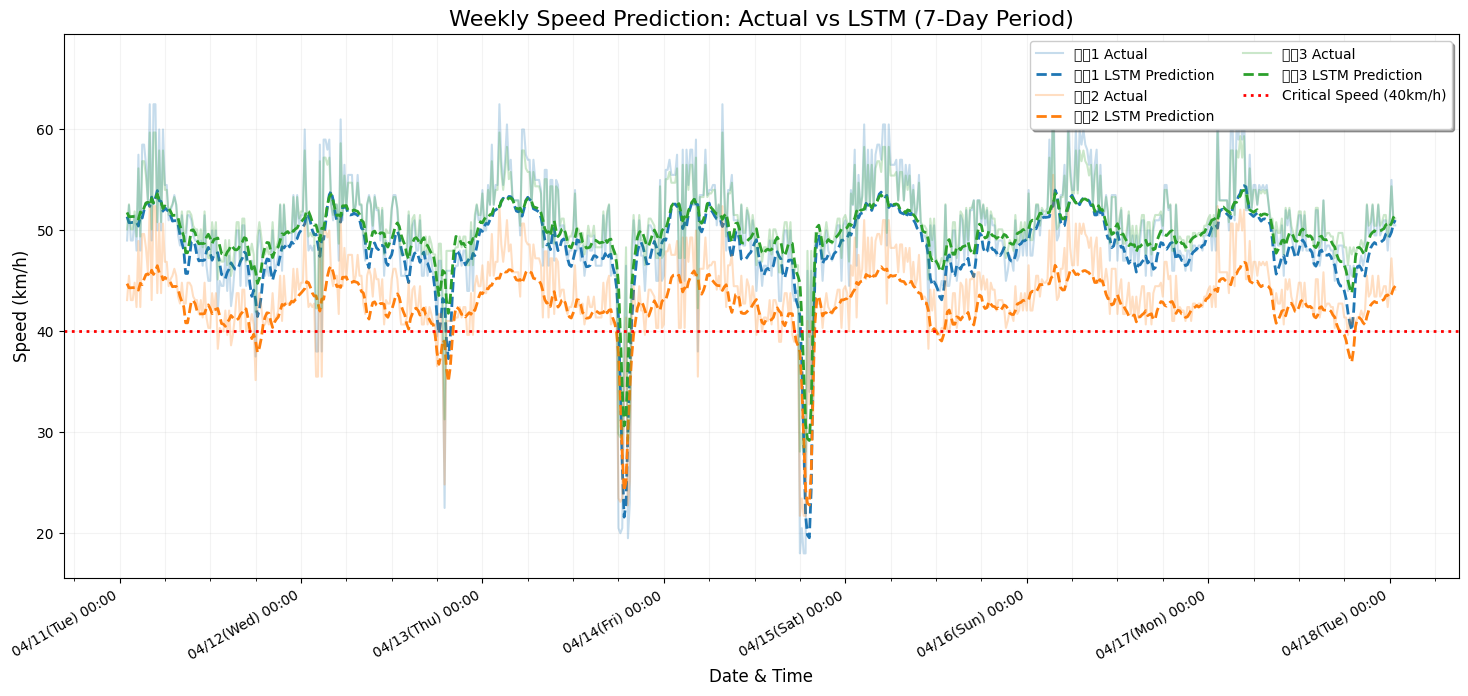

In [ ]:
import matplotlib.dates as mdates

# 1. 시각화할 범위 설정 (7일치 = 24시간 * 4(15분단위) * 7일 = 672개)
# 데이터가 672개보다 적을 경우를 대비해 len(y_test)와 비교합니다.
sample_n = min(672, len(y_test))

# 테스트 데이터의 시작 지점을 계산하여 실제 시간을 가져옵니다.
start_idx = len(df_final) - len(y_test)
time_axis = df_final['열1'].iloc[start_idx : start_idx + sample_n]

# 2. 그래프 설정
plt.figure(figsize=(18, 8))

# 각 구간별 실제/예측 데이터 추출 및 그리기
for i, sec in enumerate(sections):
    # 테스트 데이터의 앞부분 sample_n개만 추출
    actual_unscaled = get_unscaled_values(y_test[:sample_n], sec)
    pred_unscaled = get_unscaled_values(y_pred[:sample_n], sec)

    # 그래프 그리기 (투명도와 두께 조절로 가독성 향상)
    plt.plot(time_axis, actual_unscaled, label=f'{sec} Actual', color=colors[i], alpha=0.25, linewidth=1.5)
    plt.plot(time_axis, pred_unscaled, label=f'{sec} LSTM Prediction', color=colors[i], linestyle='--', linewidth=2)

# 3. 임계 속도 기준선
plt.axhline(y=40, color='red', linestyle=':', linewidth=2, label='Critical Speed (40km/h)')

# 4. X축 시간 포맷 설정 (7일치에 최적화)
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m/%d(%a) %H:%M')) # '월/일(요일) 시:분'
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=1)) # 1일 단위로 날짜 표시
plt.gca().xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18])) # 6시간마다 보조 눈금
plt.gcf().autofmt_xdate()

# 5. 그래프 꾸미기
plt.title('Weekly Speed Prediction: Actual vs LSTM (7-Day Period)', fontsize=16)
plt.xlabel('Date & Time', fontsize=12)
plt.ylabel('Speed (km/h)', fontsize=12)
plt.legend(loc='upper right', ncol=2, frameon=True, shadow=True)
plt.grid(True, which='both', alpha=0.15)

plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


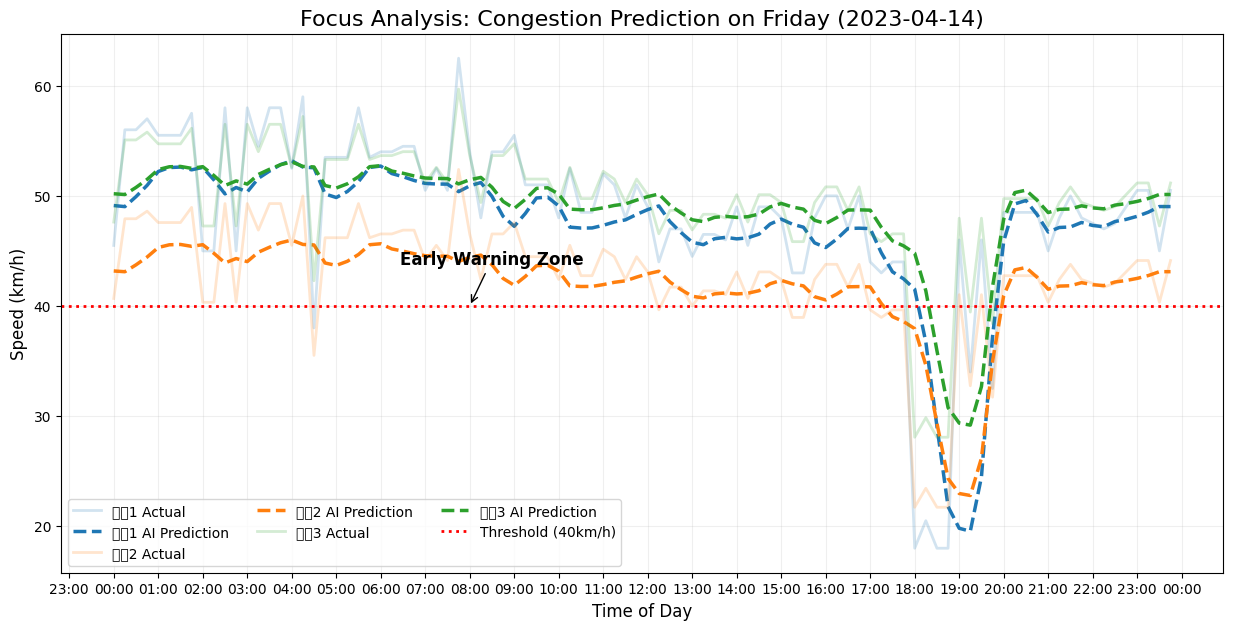

In [ ]:
# 1. 특정 날짜(금요일) 데이터 필터링
# 테스트 데이터가 포함된 시간 축(time_axis)에서 4월 14일만 추출합니다.
target_date = '2023-04-14' # 분석 중인 데이터의 실제 연도에 맞춰 수정하세요.
friday_mask = time_axis.dt.strftime('%Y-%m-%d') == target_date

# 금요일 데이터가 있는 인덱스 범위 확인
friday_indices = np.where(friday_mask)[0]

if len(friday_indices) > 0:
    start_f = friday_indices[0]
    end_f = friday_indices[-1]

    time_friday = time_axis.iloc[start_f:end_f+1]
    y_test_friday = y_test[start_f:end_f+1]
    y_pred_friday = y_pred[start_f:end_f+1]

    # 2. 그래프 설정
    plt.figure(figsize=(15, 7))

    for i, sec in enumerate(sections):
        actual_f = get_unscaled_values(y_test_friday, sec)
        pred_f = get_unscaled_values(y_pred_friday, sec)

        # 실제값(희미한 실선)과 예측값(진한 점선)
        plt.plot(time_friday, actual_f, label=f'{sec} Actual', color=colors[i], alpha=0.2, linewidth=2)
        plt.plot(time_friday, pred_f, label=f'{sec} AI Prediction', color=colors[i], linestyle='--', linewidth=2.5)

    # 3. 임계 속도 기준선 및 정체 강조
    plt.axhline(y=40, color='red', linestyle=':', linewidth=2, label='Threshold (40km/h)')

    # 4. X축 시간 포맷 (금요일 하루치이므로 1시간 단위 표시)
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    plt.gca().xaxis.set_major_locator(mdates.HourLocator(interval=1))

    # 5. 그래프 꾸미기
    plt.title(f'Focus Analysis: Congestion Prediction on Friday ({target_date})', fontsize=16)
    plt.xlabel('Time of Day', fontsize=12)
    plt.ylabel('Speed (km/h)', fontsize=12)
    plt.legend(loc='lower left', ncol=3)
    plt.grid(True, alpha=0.2)

    # 정체 시점 주석 추가 (예: 오전 8시경 급락 지점)
    plt.annotate('Early Warning Zone', xy=(time_friday.iloc[len(time_friday)//3], 40),
                 xytext=(-50, 30), textcoords='offset points',
                 arrowprops=dict(arrowstyle='->', color='black'), fontsize=12, fontweight='bold')

    plt.show()
else:
    print(f"데이터셋 내에 {target_date}에 해당하는 데이터가 없습니다.")